# 6 — SHAP interpretability for Logistic Regression

We explain **CV-tuned logistic regression** models trained on each equivalence arm from notebook 5:

| Arm | Training data |
|-----|----------------|
| **R** | Real train fold only |
| **S** | Synthetic pool (size-matched to train) |
| **R+S** | Real train + synthetic top-up to 2× train size |

SHAP values are computed with `shap.LinearExplainer` on the **preprocessed feature matrix** (scaled numerics + NHANES categorical codes 1/2). We explain **P(low BMD)** (positive class).

**Evaluation cohorts** (always real data, never used for training):

1. **Internal test** — 30% development hold-out
2. **External validation** — NHANES 2013–2014 complete cases

For each arm we show **mean |SHAP|** bar charts and **beeswarm** plots, then compare how the evaluation cohort shifts feature rankings across arms.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import seaborn as sns

from experiment_utils import (
    TRAIN_PATH,
    TEST_PATH,
    EXTERNAL_CLEAN_PATH,
    CTGAN_POOL_PATH,
    FIGURES_DIR,
    MODEL_FEATURES,
    LABEL_COL,
    RANDOM_STATE,
    NHANES_TO_PAPER,
    train_model,
    evaluate_model,
    stratified_subsample,
    ensure_dirs,
)

warnings.filterwarnings('ignore', category=FutureWarning)
ensure_dirs()

PAPER_LABELS = [NHANES_TO_PAPER[c] for c in MODEL_FEATURES]
ARM_ORDER = ['R (real)', 'S (synthetic)', 'R+S (augmented)']
EVAL_ORDER = ['Internal test', 'External 2013–14']
TOP_N = 12

/Users/vassilis/Documents/OP_article/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 6.1 Load data and build training arms

In [2]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
external_df = pd.read_csv(EXTERNAL_CLEAN_PATH)
synthetic_pool = pd.read_csv(CTGAN_POOL_PATH)

n_train = len(train_df)
synthetic_matched = stratified_subsample(
    synthetic_pool, n=n_train, random_state=RANDOM_STATE,
)
synthetic_extra = stratified_subsample(
    synthetic_pool, n=n_train, random_state=RANDOM_STATE + 1,
)
train_augmented = pd.concat([train_df, synthetic_extra], ignore_index=True)

arms = {
    'R (real)': train_df,
    'S (synthetic)': synthetic_matched,
    'R+S (augmented)': train_augmented,
}
eval_sets = {
    'Internal test': test_df,
    'External 2013–14': external_df,
}

for name, df in arms.items():
    print(f'{name:18s} N={len(df):5d}  TARGET={df[LABEL_COL].mean():.3f}')
print()
for name, df in eval_sets.items():
    print(f'{name:18s} N={len(df):5d}  TARGET={df[LABEL_COL].mean():.3f}')

R (real)           N= 1813  TARGET=0.474
S (synthetic)      N= 1813  TARGET=0.472
R+S (augmented)    N= 3626  TARGET=0.473

Internal test      N=  778  TARGET=0.474
External 2013–14   N= 1728  TARGET=0.492


## 6.2 Train LR models (one per arm)

In [3]:
lr_models = {}
lr_metrics = []

for arm_name, train_arm in arms.items():
    print(f'Training LR on {arm_name}...')
    model = train_model(
        train_arm[MODEL_FEATURES],
        train_arm[LABEL_COL],
        model_name='LR',
    )
    lr_models[arm_name] = model

    for eval_name, eval_df in eval_sets.items():
        metrics = evaluate_model(model, eval_df, eval_df[LABEL_COL])
        lr_metrics.append({
            'arm': arm_name,
            'eval': eval_name,
            'auc': metrics['auc'],
            'n': len(eval_df),
        })

metrics_df = pd.DataFrame(lr_metrics)
print('\nLR performance by arm and evaluation cohort:')
print(metrics_df.pivot(index='arm', columns='eval', values='auc').loc[ARM_ORDER].to_string())

Training LR on R (real)...
Training LR on S (synthetic)...
Training LR on R+S (augmented)...

LR performance by arm and evaluation cohort:
eval             External 2013–14  Internal test
arm                                             
R (real)                 0.765476       0.771496
S (synthetic)            0.738166       0.753354
R+S (augmented)          0.760694       0.768104


## 6.3 SHAP helpers and computation

`LinearExplainer` uses the **training-arm background** (preprocessed training matrix) and explains each evaluation row's contribution to **P(low BMD)**.

In [4]:
def transform_matrix(model, df: pd.DataFrame) -> np.ndarray:
    return model.named_steps['prep'].transform(df[MODEL_FEATURES])


def compute_shap_values(model, train_arm: pd.DataFrame, eval_df: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    clf = model.named_steps['clf']
    X_bg = transform_matrix(model, train_arm)
    X_eval = transform_matrix(model, eval_df)
    explainer = shap.LinearExplainer(clf, X_bg)
    shap_values = explainer.shap_values(X_eval)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
    return shap_values, X_eval


def mean_abs_shap_table(shap_values: np.ndarray) -> pd.DataFrame:
    return (
        pd.DataFrame({
            'feature': PAPER_LABELS,
            'mean_abs_shap': np.abs(shap_values).mean(axis=0),
        })
        .sort_values('mean_abs_shap', ascending=False)
        .reset_index(drop=True)
    )


def plot_mean_shap_bar(
    imp_df: pd.DataFrame,
    *,
    title: str,
    ax=None,
    color: str = 'steelblue',
    top_n: int = TOP_N,
):
    plot_df = imp_df.head(top_n).iloc[::-1]
    created_ax = ax is None
    if created_ax:
        _, ax = plt.subplots(figsize=(8, 0.45 * top_n + 1.5))
    ax.barh(plot_df['feature'], plot_df['mean_abs_shap'], color=color)
    ax.set_xlabel('Mean |SHAP|')
    ax.set_title(title)
    ax.grid(axis='x', alpha=0.3)
    if created_ax:
        plt.tight_layout()
    return ax


def plot_beeswarm(
    shap_values: np.ndarray,
    X_eval: np.ndarray,
    *,
    title: str,
    max_display: int = TOP_N,
):
    plt.figure(figsize=(9, 0.45 * max_display + 2.5))
    shap.summary_plot(
        shap_values,
        X_eval,
        feature_names=PAPER_LABELS,
        max_display=max_display,
        plot_type='dot',
        show=False,
    )
    plt.title(title, fontsize=13)
    plt.tight_layout()


shap_cache: dict[tuple[str, str], dict] = {}
importance_rows = []

for arm_name in ARM_ORDER:
    model = lr_models[arm_name]
    train_arm = arms[arm_name]
    for eval_name in EVAL_ORDER:
        eval_df = eval_sets[eval_name]
        sv, X_eval = compute_shap_values(model, train_arm, eval_df)
        imp = mean_abs_shap_table(sv)
        shap_cache[(arm_name, eval_name)] = {
            'shap_values': sv,
            'X_eval': X_eval,
            'importance': imp,
        }
        for _, row in imp.iterrows():
            importance_rows.append({
                'arm': arm_name,
                'eval': eval_name,
                'feature': row['feature'],
                'mean_abs_shap': row['mean_abs_shap'],
            })
        print(f'{arm_name} → {eval_name}: top feature = {imp.iloc[0]["feature"]} '
              f'(mean |SHAP| = {imp.iloc[0]["mean_abs_shap"]:.3f})')

importance_df = pd.DataFrame(importance_rows)
importance_df.to_csv(FIGURES_DIR / 'shap_lr_mean_abs.csv', index=False)
print(f'\nSaved {FIGURES_DIR / "shap_lr_mean_abs.csv"}')

R (real) → Internal test: top feature = Gender (mean |SHAP| = 0.608)
R (real) → External 2013–14: top feature = Gender (mean |SHAP| = 0.608)
S (synthetic) → Internal test: top feature = Gender (mean |SHAP| = 0.530)
S (synthetic) → External 2013–14: top feature = Gender (mean |SHAP| = 0.523)
R+S (augmented) → Internal test: top feature = Gender (mean |SHAP| = 0.518)
R+S (augmented) → External 2013–14: top feature = Gender (mean |SHAP| = 0.517)

Saved /Users/vassilis/Documents/OP_article/DATA/figures/shap_lr_mean_abs.csv


## 6.4 SHAP by training arm

For each arm: **internal test vs external validation** side by side (mean |SHAP| and beeswarm).

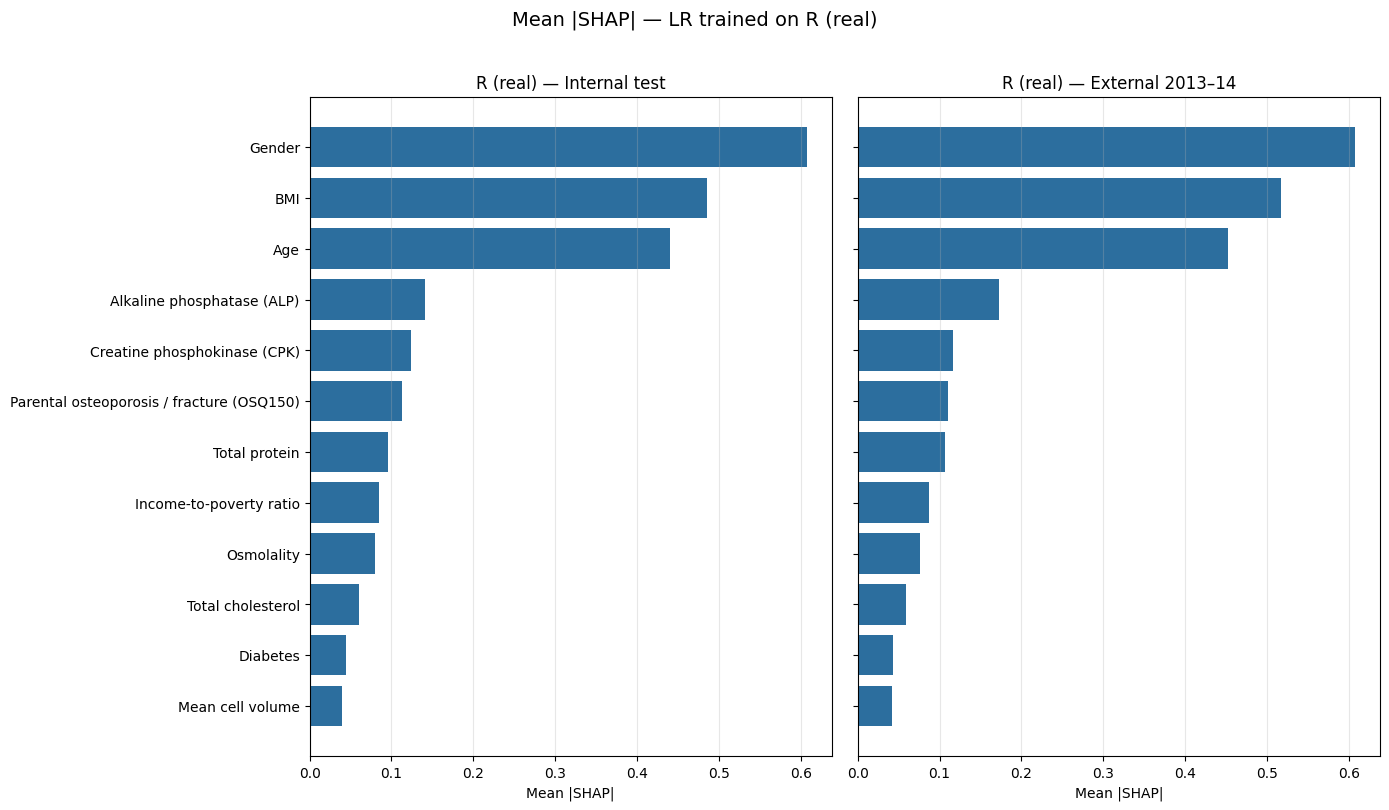

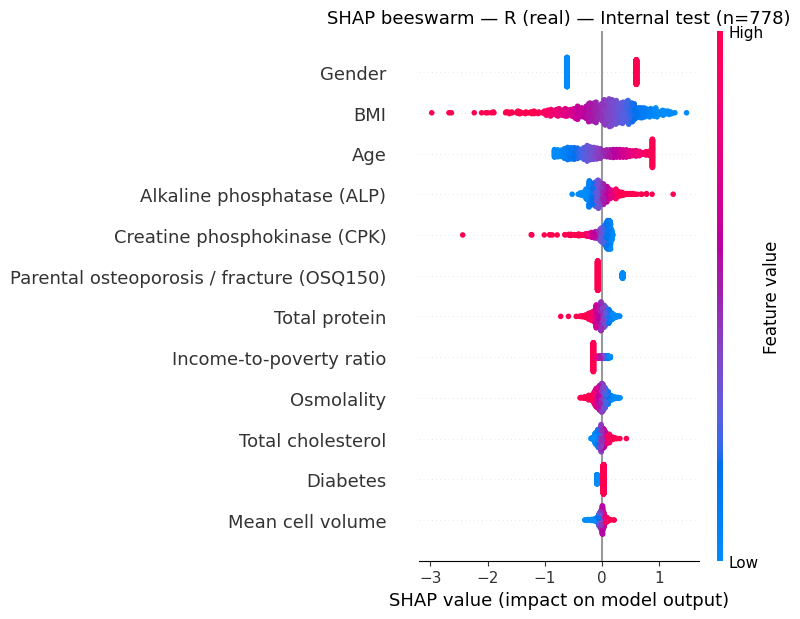

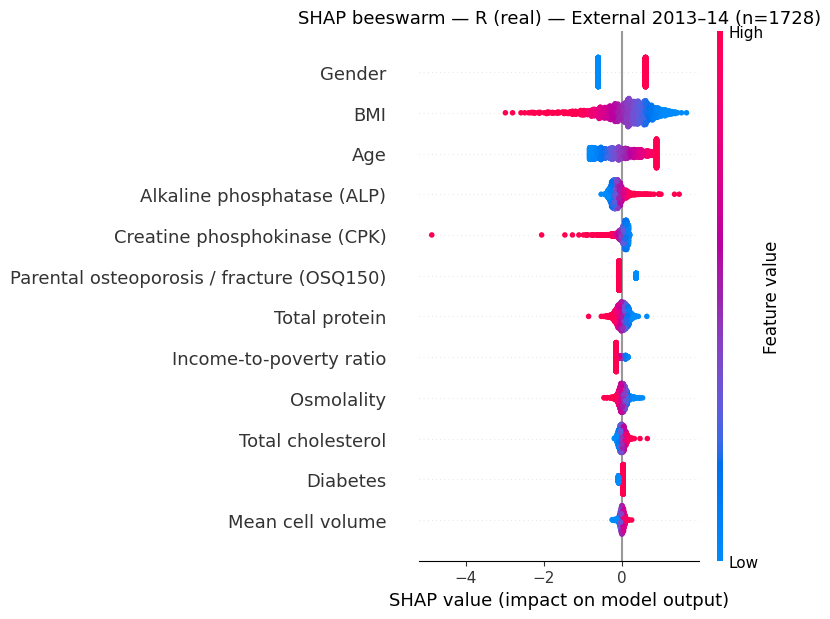

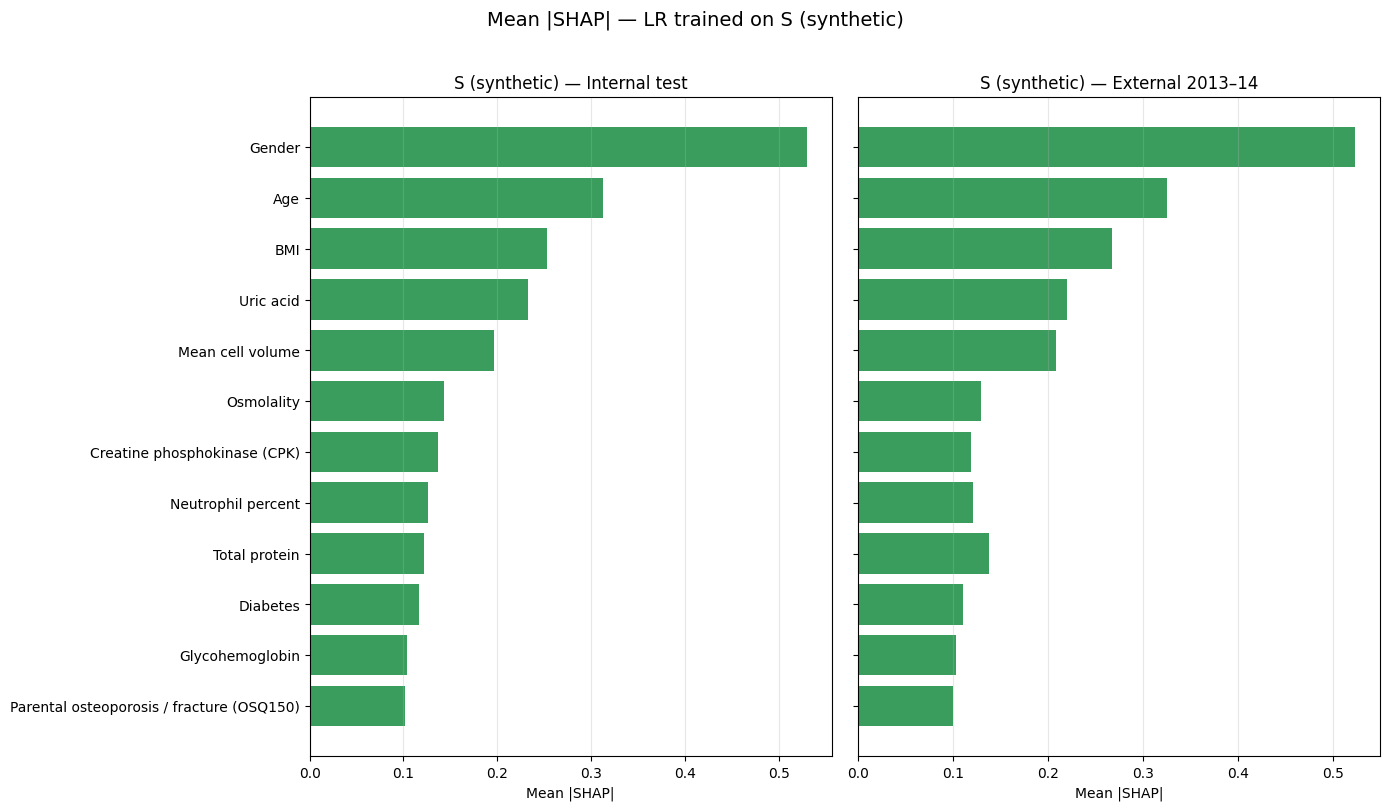

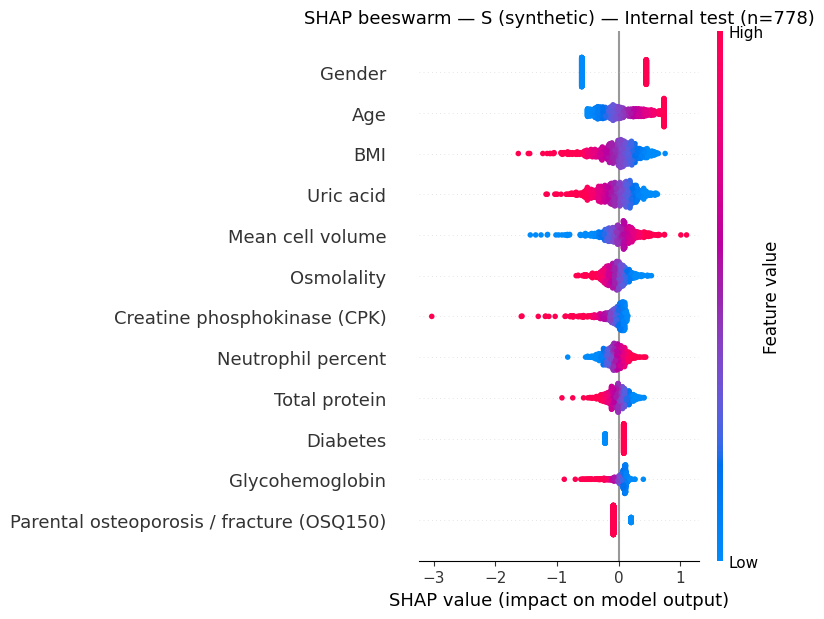

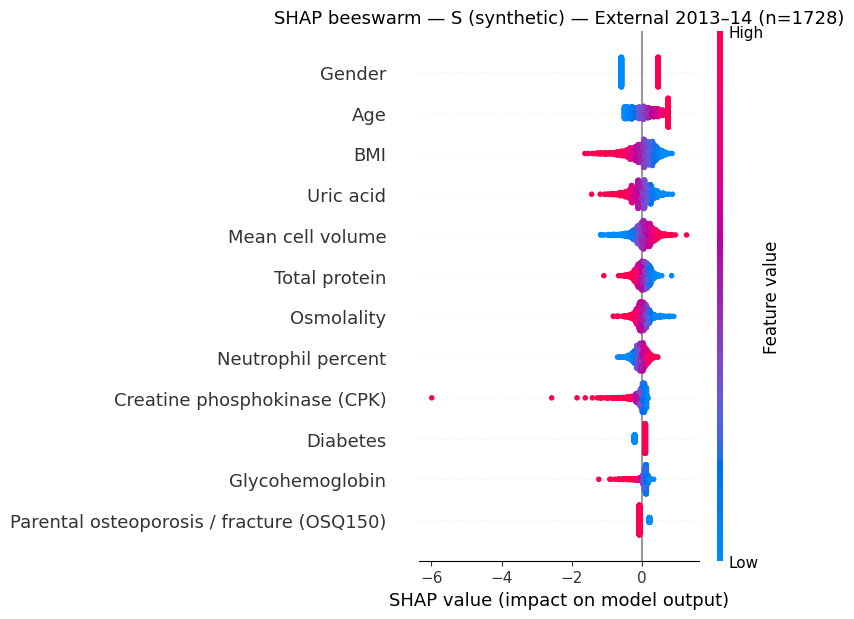

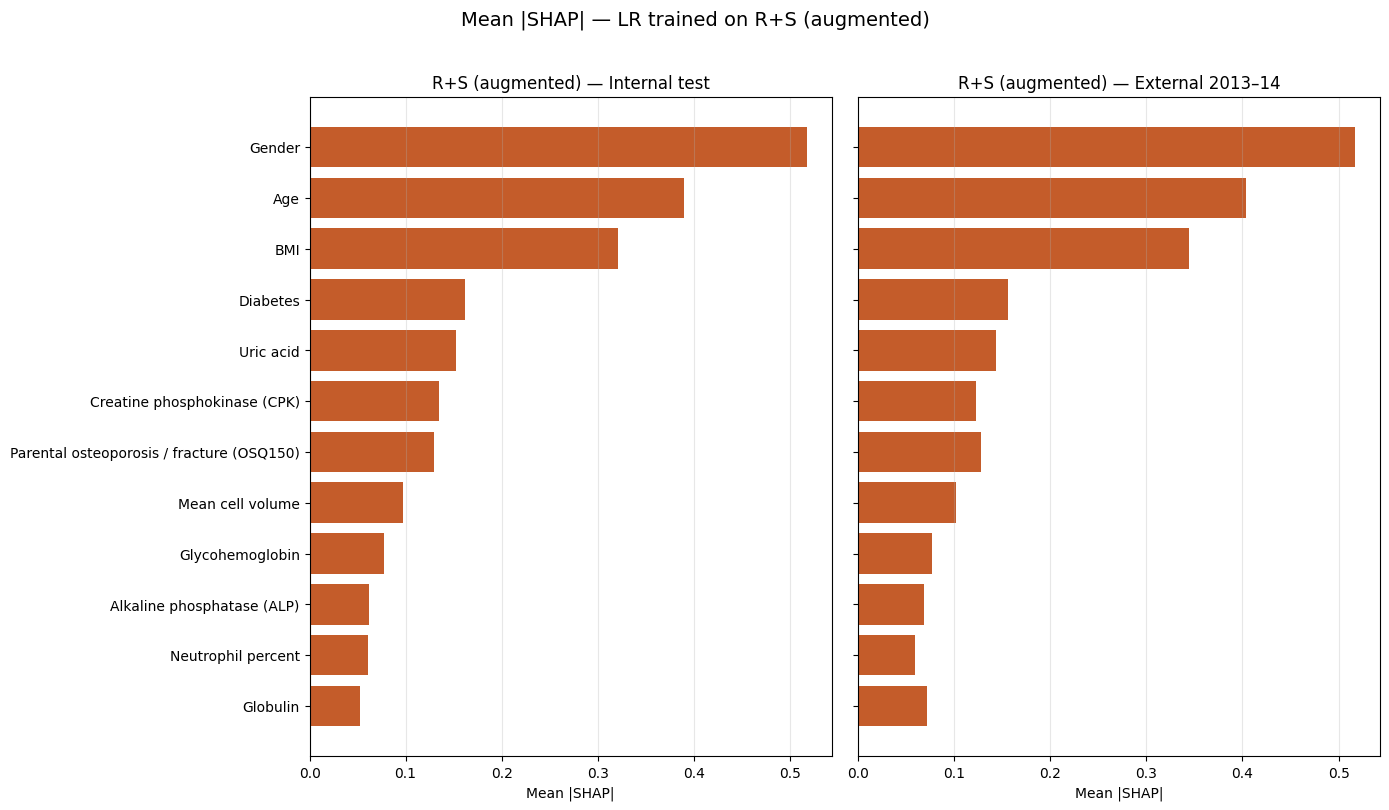

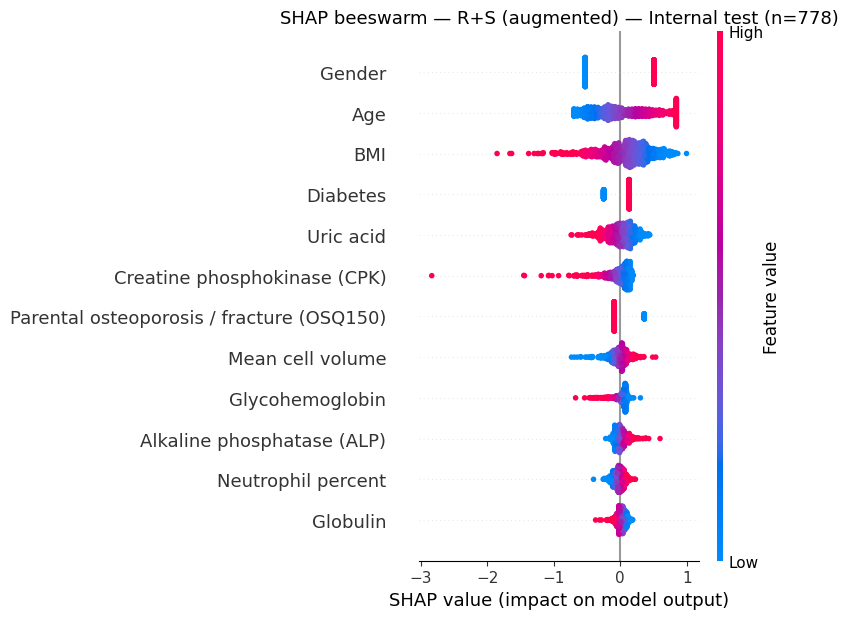

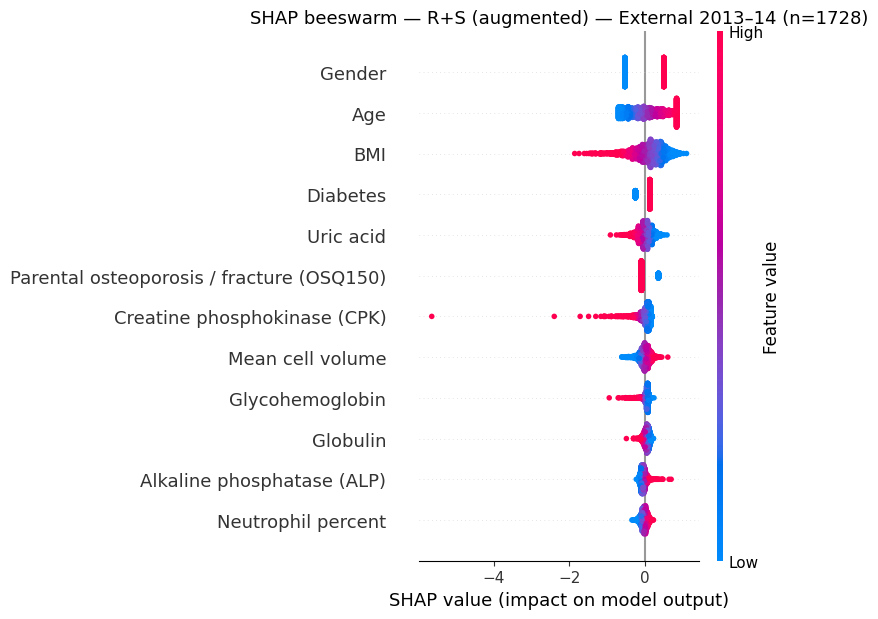

In [5]:
ARM_COLORS = {
    'R (real)': '#2c6e9e',
    'S (synthetic)': '#3a9d5d',
    'R+S (augmented)': '#c45c2a',
}

for arm_name in ARM_ORDER:
    color = ARM_COLORS[arm_name]
    fig, axes = plt.subplots(1, 2, figsize=(14, 0.45 * TOP_N + 2.5), sharey=True)
    for ax, eval_name in zip(axes, EVAL_ORDER):
        imp = shap_cache[(arm_name, eval_name)]['importance']
        plot_mean_shap_bar(
            imp,
            title=f'{arm_name} — {eval_name}',
            ax=ax,
            color=color,
        )
    fig.suptitle(f'Mean |SHAP| — LR trained on {arm_name}', fontsize=14, y=1.02)
    plt.tight_layout()
    slug = arm_name.split()[0].lower().replace('+', 'plus')
    plt.savefig(FIGURES_DIR / f'shap_lr_mean_{slug}.png', dpi=150, bbox_inches='tight')
    plt.show()

    for eval_name in EVAL_ORDER:
        payload = shap_cache[(arm_name, eval_name)]
        plot_beeswarm(
            payload['shap_values'],
            payload['X_eval'],
            title=f'SHAP beeswarm — {arm_name} — {eval_name} (n={payload["X_eval"].shape[0]})',
        )
        eval_slug = 'internal' if eval_name.startswith('Internal') else 'external'
        plt.savefig(
            FIGURES_DIR / f'shap_lr_beeswarm_{slug}_{eval_slug}.png',
            dpi=150,
            bbox_inches='tight',
        )
        plt.show()

## 6.5 Effect of evaluation cohort (internal vs external)

Grouped bars for the top features: same model, two real evaluation sets — how much do SHAP rankings shift?

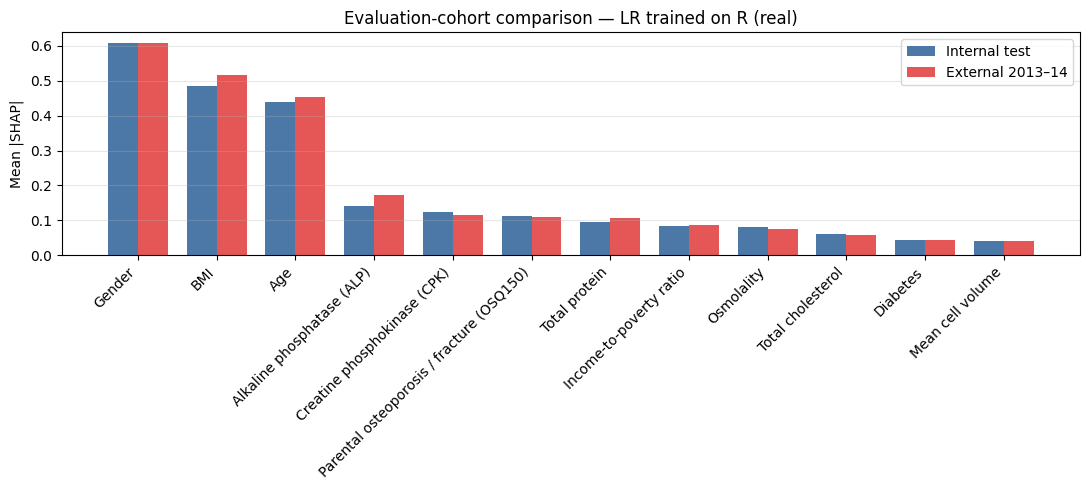


R (real) — top-12 feature ranks (internal vs external):
                                  feature  rank_internal  rank_external  mean_abs_internal  mean_abs_external
                                   Gender              1              1           0.607641           0.607641
                                      BMI              2              2           0.485428           0.516867
                                      Age              3              3           0.439840           0.452838
               Alkaline phosphatase (ALP)              4              4           0.140534           0.172889
             Creatine phosphokinase (CPK)              5              5           0.124334           0.116274
Parental osteoporosis / fracture (OSQ150)              6              6           0.113160           0.110724
                            Total protein              7              7           0.095466           0.106910
                  Income-to-poverty ratio              8       

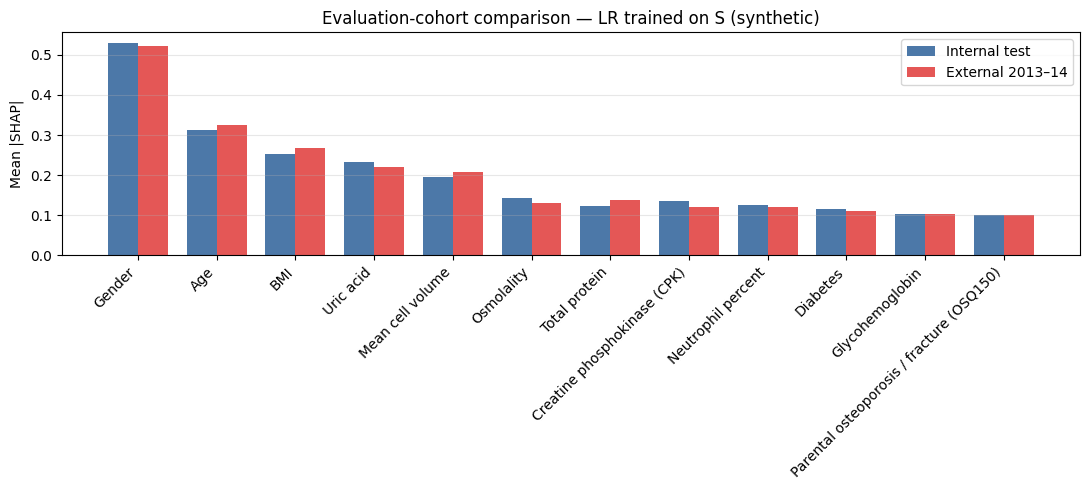


S (synthetic) — top-12 feature ranks (internal vs external):
                                  feature  rank_internal  rank_external  mean_abs_internal  mean_abs_external
                                   Gender              1              1           0.529746           0.523257
                                      Age              2              2           0.312557           0.325852
                                      BMI              3              3           0.253296           0.267134
                                Uric acid              4              4           0.232580           0.220292
                         Mean cell volume              5              5           0.196684           0.208216
                               Osmolality              6              7           0.143600           0.129953
                            Total protein              9              6           0.122110           0.138276
             Creatine phosphokinase (CPK)              7  

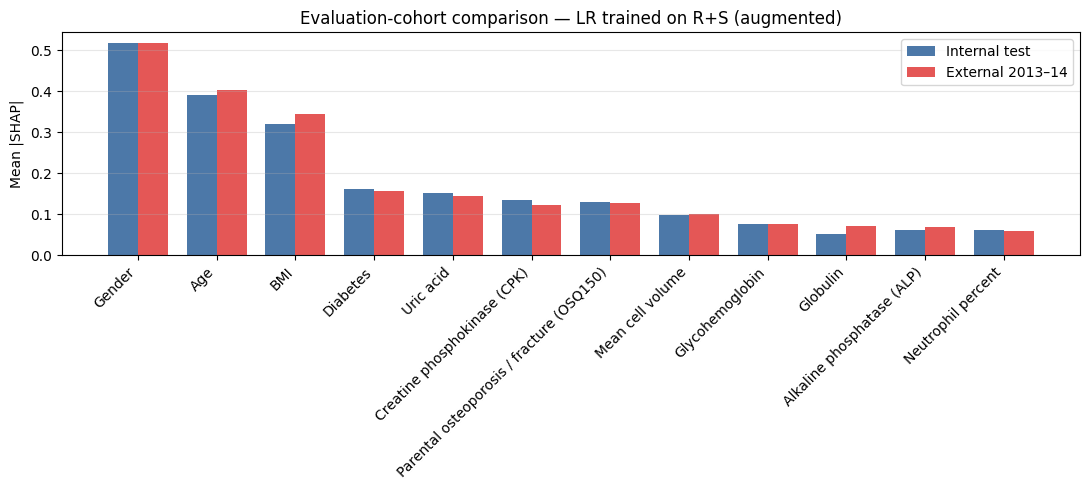


R+S (augmented) — top-12 feature ranks (internal vs external):
                                  feature  rank_internal  rank_external  mean_abs_internal  mean_abs_external
                                   Gender              1              1           0.518059           0.517143
                                      Age              2              2           0.390015           0.403321
                                      BMI              3              3           0.321212           0.344380
                                 Diabetes              4              4           0.161446           0.156663
                                Uric acid              5              5           0.152684           0.143817
             Creatine phosphokinase (CPK)              6              7           0.135053           0.122904
Parental osteoporosis / fracture (OSQ150)              7              6           0.129980           0.127754
                         Mean cell volume              8

In [6]:
for arm_name in ARM_ORDER:
    imp_internal = shap_cache[(arm_name, 'Internal test')]['importance']
    imp_external = shap_cache[(arm_name, 'External 2013–14')]['importance']
    merged = imp_internal.merge(
        imp_external,
        on='feature',
        suffixes=('_internal', '_external'),
    )
    merged['max_shap'] = merged[['mean_abs_shap_internal', 'mean_abs_shap_external']].max(axis=1)
    top_features = merged.nlargest(TOP_N, 'max_shap')['feature'].tolist()

    plot_df = merged[merged['feature'].isin(top_features)].set_index('feature').loc[top_features]
    x = np.arange(len(top_features))
    width = 0.38

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(x - width / 2, plot_df['mean_abs_shap_internal'], width, label='Internal test', color='#4c78a8')
    ax.bar(x + width / 2, plot_df['mean_abs_shap_external'], width, label='External 2013–14', color='#e45756')
    ax.set_xticks(x)
    ax.set_xticklabels(top_features, rotation=45, ha='right')
    ax.set_ylabel('Mean |SHAP|')
    ax.set_title(f'Evaluation-cohort comparison — LR trained on {arm_name}')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f'\n{arm_name} — top-{TOP_N} feature ranks (internal vs external):')
    rank_internal = {f: i + 1 for i, f in enumerate(imp_internal['feature'])}
    rank_external = {f: i + 1 for i, f in enumerate(imp_external['feature'])}
    compare = pd.DataFrame({
        'feature': top_features,
        'rank_internal': [rank_internal[f] for f in top_features],
        'rank_external': [rank_external[f] for f in top_features],
        'mean_abs_internal': plot_df['mean_abs_shap_internal'].values,
        'mean_abs_external': plot_df['mean_abs_shap_external'].values,
    })
    print(compare.to_string(index=False))

## 6.6 Cross-arm comparison (same evaluation cohort)

Heatmaps of mean |SHAP| across training arms for each evaluation set.

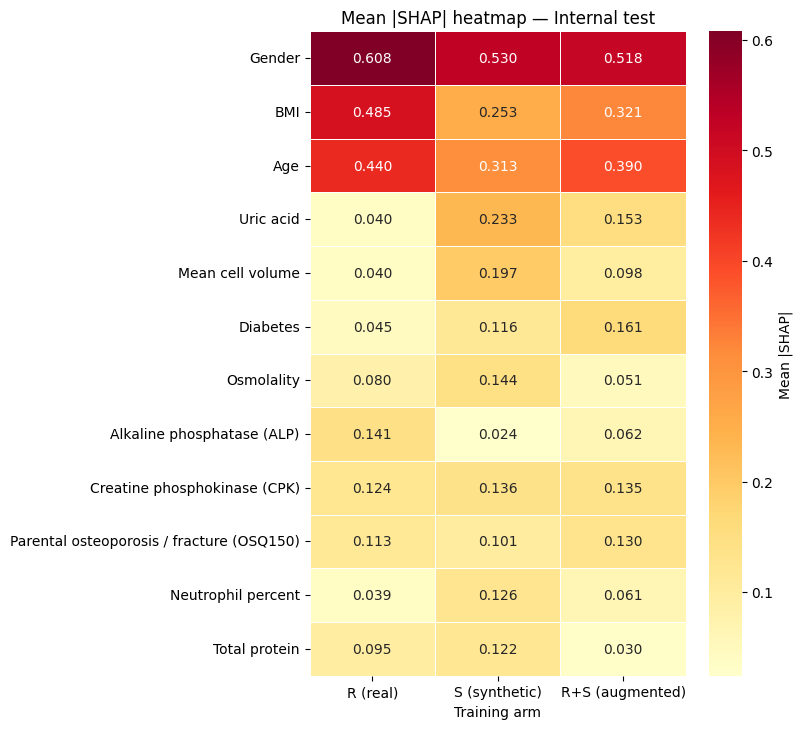

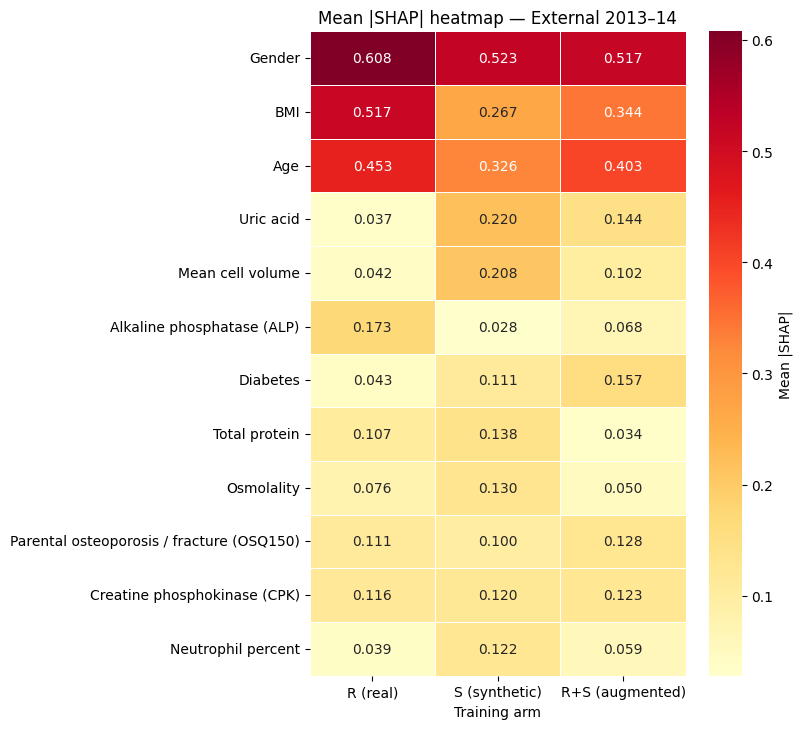

In [7]:
for eval_name in EVAL_ORDER:
    pivot = importance_df[importance_df['eval'] == eval_name].pivot(
        index='feature', columns='arm', values='mean_abs_shap',
    )[ARM_ORDER]
    top_features = pivot.max(axis=1).nlargest(TOP_N).index.tolist()
    heat = pivot.loc[top_features]

    fig, ax = plt.subplots(figsize=(8, 0.45 * TOP_N + 2))
    sns.heatmap(
        heat,
        annot=True,
        fmt='.3f',
        cmap='YlOrRd',
        linewidths=0.5,
        cbar_kws={'label': 'Mean |SHAP|'},
        ax=ax,
    )
    ax.set_title(f'Mean |SHAP| heatmap — {eval_name}')
    ax.set_xlabel('Training arm')
    ax.set_ylabel('')
    plt.tight_layout()
    slug = 'internal' if eval_name.startswith('Internal') else 'external'
    plt.savefig(FIGURES_DIR / f'shap_lr_heatmap_{slug}.png', dpi=150, bbox_inches='tight')
    plt.show()

## 6.7 Full grid — all arm × evaluation combinations

Six-panel overview (3 training arms × 2 evaluation cohorts) for publication-ready comparison.

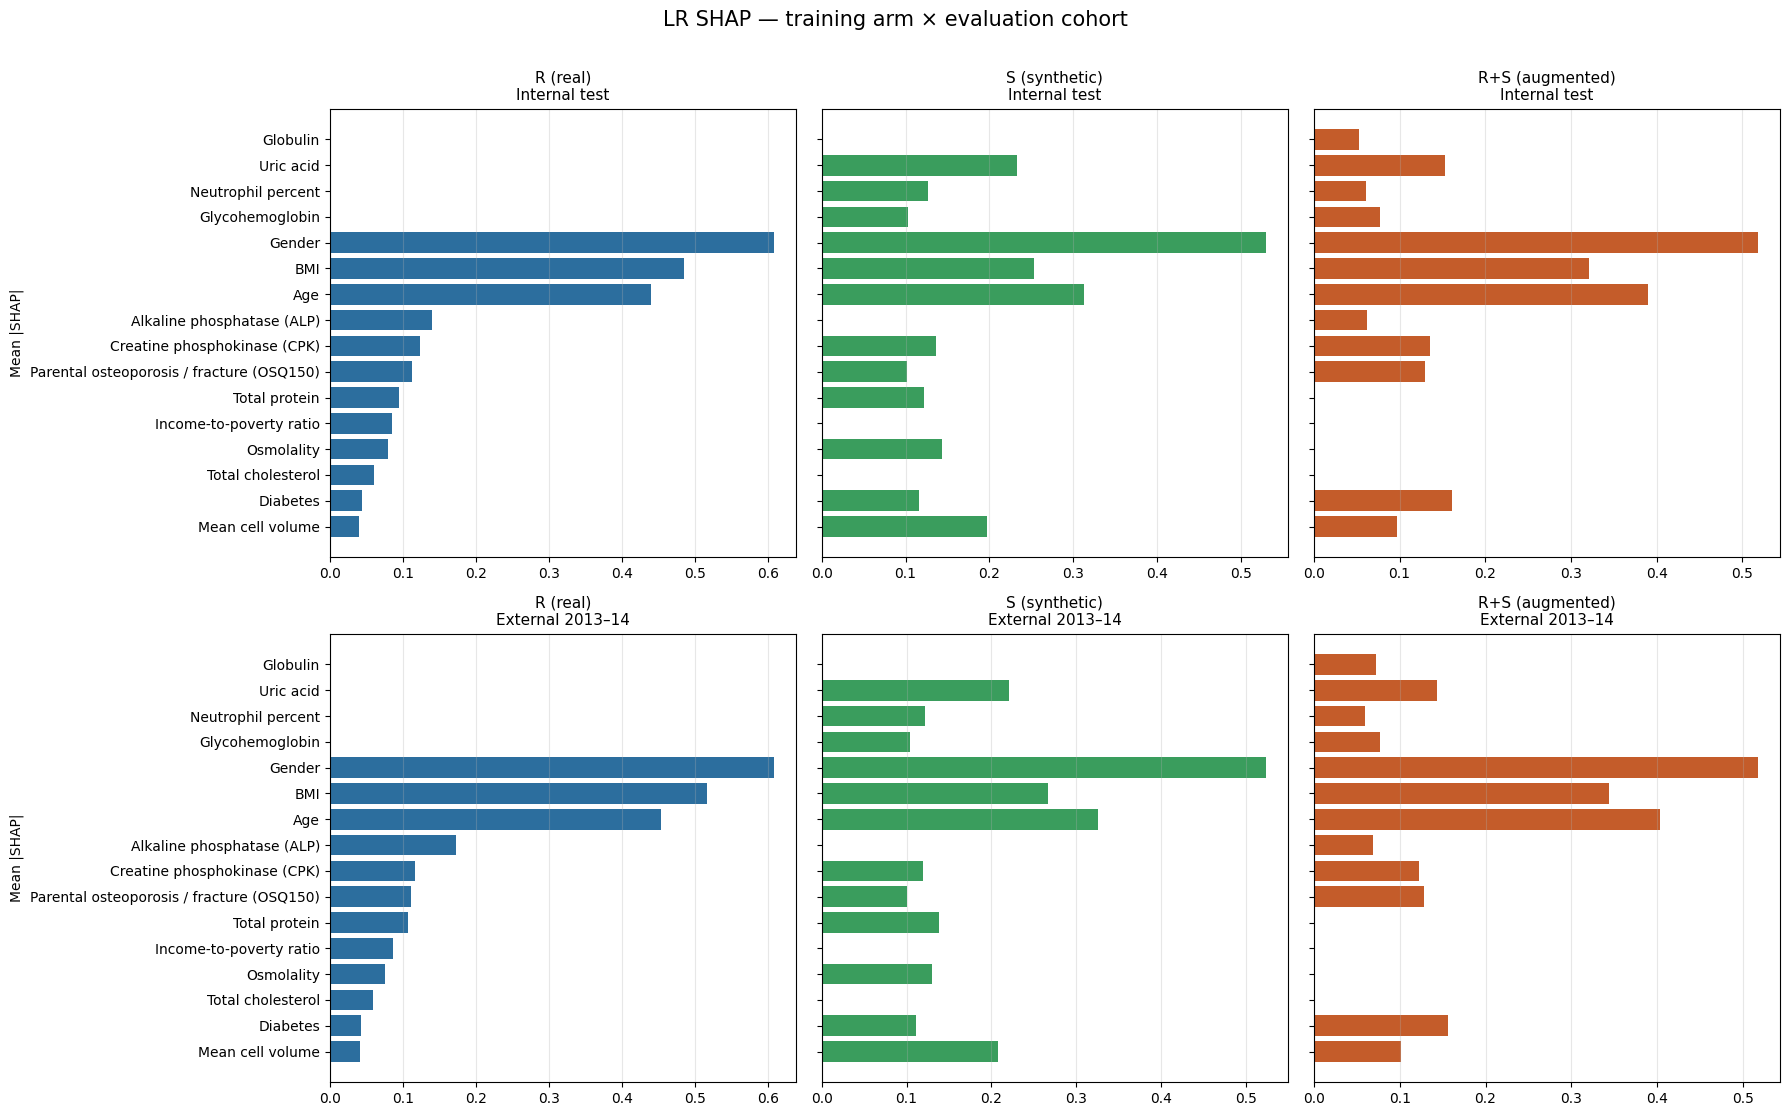

In [8]:
fig, axes = plt.subplots(len(EVAL_ORDER), len(ARM_ORDER), figsize=(18, 11), sharey='row')

for i, eval_name in enumerate(EVAL_ORDER):
    for j, arm_name in enumerate(ARM_ORDER):
        ax = axes[i, j]
        imp = shap_cache[(arm_name, eval_name)]['importance'].head(TOP_N).iloc[::-1]
        ax.barh(imp['feature'], imp['mean_abs_shap'], color=ARM_COLORS[arm_name])
        ax.set_title(f'{arm_name}\n{eval_name}', fontsize=11)
        if j == 0:
            ax.set_ylabel('Mean |SHAP|')
        else:
            ax.set_ylabel('')
        ax.grid(axis='x', alpha=0.3)

fig.suptitle('LR SHAP — training arm × evaluation cohort', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'shap_lr_grid_mean_abs.png', dpi=150, bbox_inches='tight')
plt.show()

## 6.8 Summary table

Top features per arm and evaluation cohort (article-style ordering check).

In [9]:
PAPER_SHAP_TOP = [
    'Age', 'BMI', 'Gender',
    'Creatine phosphokinase (CPK)', 'Total cholesterol', 'Alkaline phosphatase (ALP)',
]

summary_rows = []
for arm_name in ARM_ORDER:
    for eval_name in EVAL_ORDER:
        imp = shap_cache[(arm_name, eval_name)]['importance'].reset_index(drop=True)
        rank_map = {feat: rank + 1 for rank, feat in enumerate(imp['feature'])}
        for paper_feat in PAPER_SHAP_TOP:
            summary_rows.append({
                'arm': arm_name,
                'eval': eval_name,
                'paper_feature': paper_feat,
                'rank': rank_map.get(paper_feat, np.nan),
                'mean_abs_shap': imp.loc[imp['feature'] == paper_feat, 'mean_abs_shap'].squeeze()
                if paper_feat in rank_map else np.nan,
            })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(FIGURES_DIR / 'shap_lr_paper_features.csv', index=False)

for eval_name in EVAL_ORDER:
    print(f'\n=== {eval_name} — published top features (Xu et al.) ===')
    sub = summary_df[summary_df['eval'] == eval_name].pivot(
        index='paper_feature', columns='arm', values='rank',
    )[ARM_ORDER]
    print(sub.loc[PAPER_SHAP_TOP].to_string())


=== Internal test — published top features (Xu et al.) ===
arm                           R (real)  S (synthetic)  R+S (augmented)
paper_feature                                                         
Age                                  3              2                2
BMI                                  2              3                3
Gender                               1              1                1
Creatine phosphokinase (CPK)         5              7                6
Total cholesterol                   10             13               17
Alkaline phosphatase (ALP)           4             15               10

=== External 2013–14 — published top features (Xu et al.) ===
arm                           R (real)  S (synthetic)  R+S (augmented)
paper_feature                                                         
Age                                  3              2                2
BMI                                  2              3                3
Gender                   

## 6.9 Rank-agreement between arms

The plots above show that the arms agree at the top of the ranking and diverge below it. This quantifies that: Spearman rank correlation against the real-data ordering (with a Fisher-z confidence interval, since 18 features is a small sample), plus displacement statistics that do not depend on a correlation estimate.

Exports `shap_lr_rank_agreement.csv` (summary) and `shap_lr_rank_table.csv` (per-feature ranks per arm).

In [10]:
from scipy.stats import norm, spearmanr


def rho_confidence_interval(rho: float, n: int, alpha: float = 0.05) -> tuple[float, float]:
    """Fisher z-transform interval for a rank correlation."""
    z = np.arctanh(rho)
    se = 1 / np.sqrt(n - 3)
    crit = norm.ppf(1 - alpha / 2)
    return np.tanh(z - crit * se), np.tanh(z + crit * se)


REFERENCE_ARM = 'R (real)'
agreement_rows = []
rank_frames = []

for eval_name in EVAL_ORDER:
    pivot = importance_df[importance_df['eval'] == eval_name].pivot(
        index='feature', columns='arm', values='mean_abs_shap',
    )[ARM_ORDER]
    ranks = pivot.rank(ascending=False).astype(int)
    rank_frames.append(
        ranks.assign(eval=eval_name).reset_index().sort_values(REFERENCE_ARM)
    )

    n_feat = len(pivot)
    reference = ranks[REFERENCE_ARM]
    top3_ref = set(reference.nsmallest(3).index)
    top5_ref = set(reference.nsmallest(5).index)

    for arm_name in ARM_ORDER[1:]:
        rho, p_value = spearmanr(reference, ranks[arm_name])
        ci_low, ci_high = rho_confidence_interval(rho, n_feat)
        shift = (ranks[arm_name] - reference).abs()
        agreement_rows.append({
            'eval': eval_name,
            'arm': arm_name,
            'n_features': n_feat,
            'spearman_rho': rho,
            'ci_low': ci_low,
            'ci_high': ci_high,
            'p_value': p_value,
            'mean_abs_rank_shift': shift.mean(),
            'median_abs_rank_shift': shift.median(),
            'max_rank_shift': int(shift.max()),
            'n_moved_5plus': int((shift >= 5).sum()),
            'top3_overlap': len(top3_ref & set(ranks[arm_name].nsmallest(3).index)),
            'top5_overlap': len(top5_ref & set(ranks[arm_name].nsmallest(5).index)),
        })

agreement_df = pd.DataFrame(agreement_rows)
agreement_df.to_csv(FIGURES_DIR / 'shap_lr_rank_agreement.csv', index=False)

rank_table = pd.concat(rank_frames, ignore_index=True)
rank_table.to_csv(FIGURES_DIR / 'shap_lr_rank_table.csv', index=False)

for _, row in agreement_df.iterrows():
    print(f"{row['eval']} | {REFERENCE_ARM} vs {row['arm']}")
    print(f"  rho = {row['spearman_rho']:.3f}  95% CI [{row['ci_low']:.2f}, {row['ci_high']:.2f}]  p = {row['p_value']:.4f}")
    print(f"  mean |rank shift| = {row['mean_abs_rank_shift']:.1f}  max = {row['max_rank_shift']}"
          f"  moved >=5 ranks: {row['n_moved_5plus']}/{row['n_features']}")
    print(f"  top-3 overlap = {row['top3_overlap']}/3   top-5 overlap = {row['top5_overlap']}/5\n")

Internal test | R (real) vs S (synthetic)
  rho = 0.501  95% CI [0.04, 0.78]  p = 0.0344
  mean |rank shift| = 3.9  max = 11  moved >=5 ranks: 6/18
  top-3 overlap = 3/3   top-5 overlap = 3/5

Internal test | R (real) vs R+S (augmented)
  rho = 0.552  95% CI [0.11, 0.81]  p = 0.0175
  mean |rank shift| = 4.1  max = 9  moved >=5 ranks: 8/18
  top-3 overlap = 3/3   top-5 overlap = 3/5

External 2013–14 | R (real) vs S (synthetic)
  rho = 0.465  95% CI [-0.00, 0.77]  p = 0.0516
  mean |rank shift| = 4.1  max = 11  moved >=5 ranks: 7/18
  top-3 overlap = 3/3   top-5 overlap = 3/5

External 2013–14 | R (real) vs R+S (augmented)
  rho = 0.501  95% CI [0.04, 0.78]  p = 0.0344
  mean |rank shift| = 4.2  max = 9  moved >=5 ranks: 9/18
  top-3 overlap = 3/3   top-5 overlap = 3/5

